# Symbolic Detective — v0.2 Class Voting Analysis

**Objective:** Analyze whether class-level aggregation of retrieved neighbors improves fine-grained motif discrimination compared with Top-1 retrieval.

**Dataset:** v0.2 expanded related-motif dataset (development partition only).

**Methodology:** 5-fold stratified, artifact-grouped cross-validation with artifact-deduplicated voting.

**Experiments:**
- DINOv2 embeddings (α=0.0) and Hybrid retrieval (α=0.25)
- Top-1 (K=1), majority voting and similarity-weighted voting (K ∈ {3,5,7}).

**Evaluation metrics:** Accuracy, macro F1, per-class precision, recall, and F1.

**Prediction Transition Analysis**:
- Compare baseline and selected-experiment predictions for identical queries and folds.
- Identify rescued, regressed, both-correct, and both-wrong predictions.
- Examine class-level changes, particularly among star motif classes.
- Group prediction changes by artifact ID to distinguish crop-level changes from effects concentrated in individual artifacts.

**Evaluation unit**: Metrics are computed at the crop level. Artifact grouping prevents cross-validation leakage, while artifact-level transition summaries are descriptive and do not represent independently computed artifact-level accuracy.

**Sources**: results/v0.2_dev_baseline/class_voting.json, results/v0.2_dev/exp*/class_voting.json, results/v0.2_dev_baseline/voting_predictions.json, and results/v0.2_dev/exp*/voting_predictions.json.

**Purpose:** Exploratory analysis and visualization of experimental results. Official evaluation metrics are generated by `evaluate.py`.

In [155]:
import json
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Select experiment
selected_experiment = "peaks"  # harmonics, peaks, pointedness, radius, central_structure

# Locate results directory
cwd = Path.cwd()

results_root = next((
        root / "results"
        for root in [cwd, *cwd.parents]
        if (root / "results/v0.2_dev_baseline/class_voting.json").is_file()), None)

if results_root is None:
    raise FileNotFoundError("Could not locate v0.2 development baseline.")

# Discover available experiments
available_paths = {
    path.parent.name.split("_", 1)[1]: path
    for path in sorted((results_root / "v0.2_dev").glob("exp*/class_voting.json"))
}

if selected_experiment not in available_paths:
    raise ValueError(f"Experiment '{selected_experiment}' not found. Available: {list(available_paths)}")

# Load baseline and selected experiment
experiment_paths = {
    "baseline": results_root / "v0.2_dev_baseline/class_voting.json",
    selected_experiment: available_paths[selected_experiment],
}

frames = []
raw_data = {}
for name, path in experiment_paths.items():
    with path.open(encoding="utf-8") as f:
        records = json.load(f)

    raw_data[name] = records
    frame = pd.json_normalize(records)
    frame.columns = frame.columns.str.removeprefix("metrics.")
    frame["experiment"] = name
    frames.append(frame)
    print(f"{name}: {path}")

df = pd.concat(frames, ignore_index=True)

print(f"\nLoaded {len(raw_data)} experiments.")
display(df.head())

baseline: C:\Users\Maja\projects\symbolic-detective\results\v0.2_dev_baseline\class_voting.json
peaks: C:\Users\Maja\projects\symbolic-detective\results\v0.2_dev\exp02_peaks\class_voting.json

Loaded 2 experiments.


,alpha,strategy,k,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean,cv_macro_f1_std,pooled_accuracy,pooled_macro_f1,per_class_metrics.eight_petal_rosette.precision,...,per_class_metrics.rosette_other.support,per_class_metrics.six_pointed_star.precision,per_class_metrics.six_pointed_star.recall,per_class_metrics.six_pointed_star.f1-score,per_class_metrics.six_pointed_star.support,per_class_metrics.sunburst.precision,per_class_metrics.sunburst.recall,per_class_metrics.sunburst.f1-score,per_class_metrics.sunburst.support,experiment
0,0.0,top1,1,0.604235,0.063553,0.598455,0.072510,0.607595,0.608185,0.555556,...,31,0.612903,0.463415,0.527778,41,0.875000,0.567568,0.688525,37,baseline
1,0.0,majority,3,0.614417,0.052993,0.608174,0.056473,0.616034,0.615819,0.523810,...,31,0.558824,0.463415,0.506667,41,0.958333,0.621622,0.754098,37,baseline
2,0.0,majority,5,0.607893,0.040202,0.601478,0.059998,0.607595,0.607834,0.523810,...,31,0.540541,0.487805,0.512821,41,0.954545,0.567568,0.711864,37,baseline
3,0.0,majority,7,0.601050,0.068451,0.589489,0.074470,0.603376,0.600977,0.536585,...,31,0.545455,0.439024,0.486486,41,1.000000,0.540541,0.701754,37,baseline
4,0.0,weighted,3,0.614417,0.052993,0.608174,0.056473,0.616034,0.615819,0.523810,...,31,0.558824,0.463415,0.506667,41,0.958333,0.621622,0.754098,37,baseline


## Baseline Voting Analysis

In [156]:
baseline = df[df["experiment"] == "baseline"]

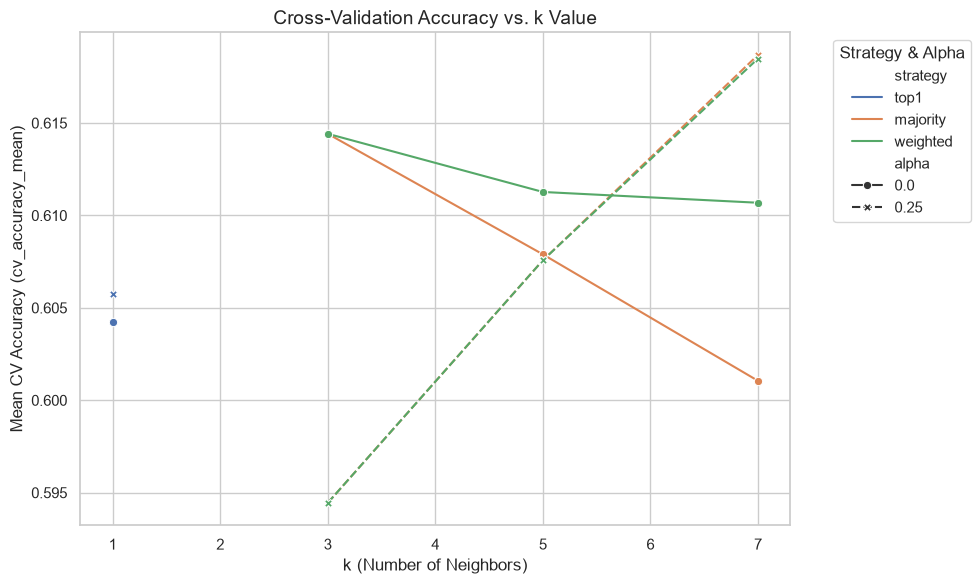

In [157]:
# Set a clean visual style
sns.set_theme(style="whitegrid")

# Create a figure with a specific size
plt.figure(figsize=(10, 6))

# Generate a line plot
# 'hue' separates lines by strategy, 'style' separates them by alpha
sns.lineplot(
    data=baseline, 
    x='k', 
    y='cv_accuracy_mean', 
    hue='strategy', 
    style='alpha',
    markers=True, # Adds dots at each data point
    dashes=True
)

# Customize the labels and title
plt.title('Cross-Validation Accuracy vs. k Value', fontsize=14)
plt.ylabel('Mean CV Accuracy (cv_accuracy_mean)')
plt.xlabel('k (Number of Neighbors)')

# Move legend outside the plot for better readability
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Strategy & Alpha')

# Display the plot
plt.tight_layout()
plt.show()

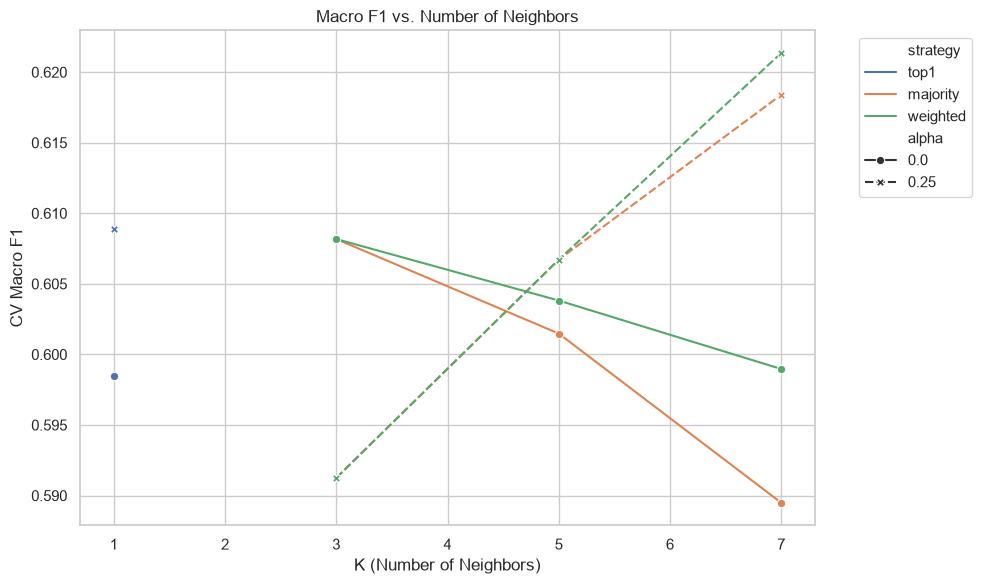

In [158]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=baseline,
    x="k",
    y="cv_macro_f1_mean",
    hue="strategy",
    style="alpha",
    markers=True,
    dashes=True,
)

plt.title("Macro F1 vs. Number of Neighbors")
plt.xlabel("K (Number of Neighbors)")
plt.ylabel("CV Macro F1")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [159]:
summary = baseline[
    ["alpha", "strategy", "k", "cv_accuracy_mean", "cv_macro_f1_mean"]
].sort_values("cv_macro_f1_mean", ascending=False)

display(summary.round(3))

,alpha,strategy,k,cv_accuracy_mean,cv_macro_f1_mean
13,0.25,weighted,7,0.618,0.621
10,0.25,majority,7,0.619,0.618
7,0.25,top1,1,0.606,0.609
1,0.00,majority,3,0.614,0.608
4,0.00,weighted,3,0.614,0.608
9,0.25,majority,5,0.608,0.607
12,0.25,weighted,5,0.608,0.607
5,0.00,weighted,5,0.611,0.604
2,0.00,majority,5,0.608,0.601
6,0.00,weighted,7,0.611,0.599


In [160]:
rows = []

for item in raw_data["baseline"]:
    for cls, metrics in item["metrics"]["per_class_metrics"].items():
        rows.append({
            "alpha": item["alpha"],
            "strategy": item["strategy"],
            "k": item["k"],
            "class": cls,
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1-score"],
            "support": metrics["support"],
        })

class_baseline = pd.DataFrame(rows)

display(class_baseline.round(3))

,alpha,strategy,k,class,precision,recall,f1,support
0,0.00,top1,1,eight_petal_rosette,0.556,0.588,0.571,34
1,0.00,top1,1,eight_pointed_star,0.672,0.750,0.709,52
2,0.00,top1,1,five_pointed_star,0.596,0.667,0.629,42
3,0.00,top1,1,rosette_other,0.500,0.548,0.523,31
4,0.00,top1,1,six_pointed_star,0.613,0.463,0.528,41
...,...,...,...,...,...,...,...,...
79,0.25,weighted,7,eight_pointed_star,0.631,0.788,0.701,52
80,0.25,weighted,7,five_pointed_star,0.618,0.500,0.553,42
81,0.25,weighted,7,rosette_other,0.640,0.516,0.571,31
82,0.25,weighted,7,six_pointed_star,0.541,0.488,0.513,41


In [161]:
comparison = class_baseline[
    (class_baseline["alpha"] == 0.25)
    & (
        ((class_baseline["strategy"] == "top1") & (class_baseline["k"] == 1))
        | ((class_baseline["strategy"] == "weighted") & (class_baseline["k"] == 7))
    )
]

display(
    comparison.pivot(
        index="class",
        columns=["strategy", "k"],
        values="f1",
    ).round(3)
)

strategy,top1,weighted
k,1,7
class,,
eight_petal_rosette,0.657,0.650
eight_pointed_star,0.655,0.701
five_pointed_star,0.578,0.553
rosette_other,0.600,0.571
six_pointed_star,0.526,0.513
sunburst,0.677,0.767


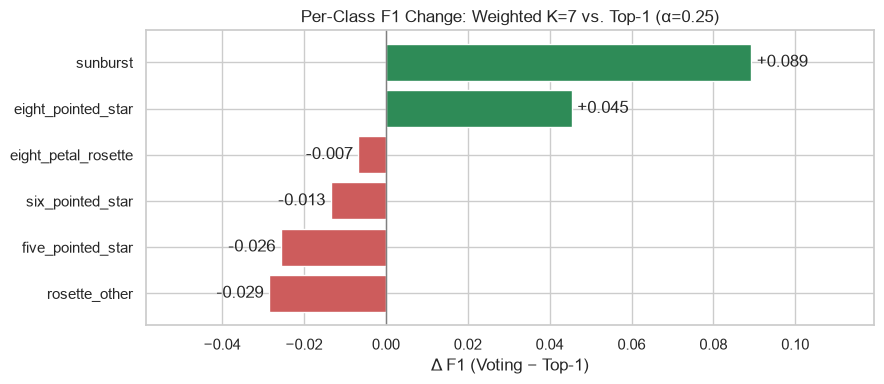

In [162]:
# Compare per-class F1: Hybrid Top-1 vs. Weighted K=7
alpha = 0.25

top1_f1 = class_baseline[
    (class_baseline["alpha"] == alpha) &
    (class_baseline["strategy"] == "top1")
].set_index("class")["f1"]

voting = class_baseline[
    (class_baseline["alpha"] == alpha) &
    (class_baseline["strategy"] == "weighted") &
    (class_baseline["k"] == 7)
].set_index("class")["f1"]

f1_diff = (voting - top1_f1).sort_values()

# Plot improvements and degradations
fig, ax = plt.subplots(figsize=(9, 4))

colors = [
    "seagreen" if value > 0 else "indianred"
    for value in f1_diff
]

bars = ax.barh(f1_diff.index, f1_diff.values, color=colors)

ax.axvline(0, color="gray", linewidth=1)
ax.bar_label(bars, fmt="%+.3f", padding=4)

ax.set_title("Per-Class F1 Change: Weighted K=7 vs. Top-1 (α=0.25)")
ax.set_xlabel("Δ F1 (Voting − Top-1)")
ax.set_xlim(f1_diff.min() - 0.03, f1_diff.max() + 0.03)

plt.tight_layout()

In [163]:
# save chart
output_dir = Path("../results/v0.2_dev_baseline/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(output_dir / "voting_f1_delta.png", dpi=300, bbox_inches="tight")
fig.savefig(output_dir / "voting_f1_delta.svg", bbox_inches="tight")

plt.show()

## Cross-Experiment Voting Analysis

Evaluate whether geometric feature improvements enhance class voting
performance relative to the development baseline.

Focus on:
- Changes in macro F1 across voting strategies and K values.
- Per-class precision, recall, and F1 changes.
- Whether geometric improvements reduce the point-counting ambiguity
  between five-, six-, and eight-pointed stars.

In [164]:

keys = ["alpha", "strategy", "k"]

base = df[df["experiment"] == "baseline"].set_index(keys)
current = df[df["experiment"] == selected_experiment].set_index(keys).reindex(base.index)

voting_comparison = pd.DataFrame({
    ("Accuracy", "Baseline"): base["cv_accuracy_mean"],
    ("Accuracy", "Baseline SD"): base["cv_accuracy_std"],
    ("Accuracy", selected_experiment): current["cv_accuracy_mean"],
    ("Accuracy", f"{selected_experiment} SD"): current["cv_accuracy_std"],
    ("Accuracy", f"Δ {selected_experiment}"): current["cv_accuracy_mean"] - base["cv_accuracy_mean"],

    ("Macro F1", "Baseline"): base["cv_macro_f1_mean"],
    ("Macro F1", "Baseline SD"): base["cv_macro_f1_std"],
    ("Macro F1", selected_experiment): current["cv_macro_f1_mean"],
    ("Macro F1", f"{selected_experiment} SD"): current["cv_macro_f1_std"],
    ("Macro F1", f"Δ {selected_experiment}"): current["cv_macro_f1_mean"] - base["cv_macro_f1_mean"],
})

In [165]:
delta_cols = [col for col in voting_comparison.columns if "Δ" in str(col) or "delta_" in str(col)]
sd_cols = [col for col in voting_comparison.columns if "SD" in str(col)]
base_cols = [col for col in voting_comparison.columns if col not in delta_cols + sd_cols]
macro_cols = [col for col in voting_comparison.columns if col[0] == "Macro F1"]

max_delta = voting_comparison[delta_cols].abs().max().max() if not voting_comparison[delta_cols].empty else 0.1

def mark_high_sd(val, threshold=0.05):
    if pd.isna(val):
        return ''
    if val > threshold:
        return 'color: #dc3545; font-weight: bold;' # Red
    return 'color: #6c757d;' # Grey


styled_comparison = voting_comparison.style.format(precision=4) \
    .background_gradient(subset=base_cols, cmap='Blues') \
    .background_gradient(subset=delta_cols, cmap='RdYlGn', vmin=-max_delta, vmax=max_delta)

if macro_cols:
    styled_comparison = styled_comparison.set_properties(
        subset=[macro_cols[0]], **{'border-left': '2px solid #555'}
    )

if sd_cols:
    styled_comparison = styled_comparison.map(mark_high_sd, threshold=0.05, subset=sd_cols)

display(styled_comparison)

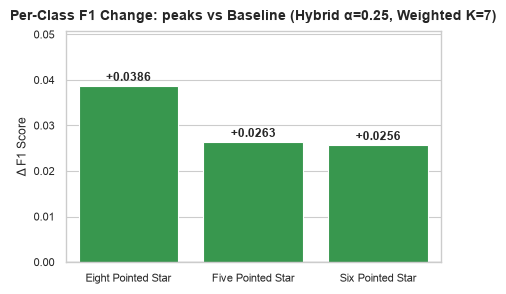

Experiment,Class,Δ Precision,Δ Recall,Δ F1
peaks,eight_pointed_star,0.0259,0.0577,0.0386
peaks,five_pointed_star,0.0294,0.0238,0.0263
peaks,six_pointed_star,0.0270,0.0244,0.0256


In [166]:
rows = []

for experiment, records in raw_data.items():
    for item in records:
        for cls, metrics in item["metrics"]["per_class_metrics"].items():
            rows.append({
                "experiment": experiment,
                "alpha": item["alpha"],
                "strategy": item["strategy"],
                "k": item["k"],
                "class": cls,
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "f1": metrics["f1-score"],
            })

per_class = pd.DataFrame(rows)

keys = ["alpha", "strategy", "k", "class"]
baseline_classes = per_class[per_class["experiment"] == "baseline"].drop(
    columns="experiment"
)

class_comparison = per_class[
    per_class["experiment"] != "baseline"
].merge(
    baseline_classes,
    on=keys,
    suffixes=("", "_baseline"),
    validate="many_to_one",
)

for metric in ["precision", "recall", "f1"]:
    class_comparison[f"delta_{metric}"] = (
        class_comparison[metric] - class_comparison[f"{metric}_baseline"]
    )

star_classes = ["five_pointed_star", "six_pointed_star", "eight_pointed_star"]

star_comparison = class_comparison[
    (class_comparison["alpha"] == 0.25)
    & (class_comparison["strategy"] == "weighted")
    & (class_comparison["k"] == 7)
    & (class_comparison["class"].isin(star_classes))
]

display_df = star_comparison[
    ["experiment", "class", "delta_precision", "delta_recall", "delta_f1"]
].copy()

display_df.columns = ["Experiment", "Class", "Δ Precision", "Δ Recall", "Δ F1"]
delta_cols = ["Δ Precision", "Δ Recall", "Δ F1"]

max_delta = display_df[delta_cols].abs().max().max() if not display_df[delta_cols].empty else 0.1

styled_stars = display_df.style.format(precision=4) \
    .background_gradient(subset=delta_cols, cmap='RdYlGn', vmin=-max_delta, vmax=max_delta) \
    .hide(axis="index")


# Plot data
plot_data = star_comparison.copy()
plot_data['class_label'] = plot_data['class'].str.replace('_', ' ').str.title()
plot_data['Improvement'] = plot_data['delta_f1'] > 0

plt.figure(figsize=(4.5, 3))
sns.set_theme(style="whitegrid")
sns.set_context("paper", font_scale=0.9)

ax = sns.barplot(
    data=plot_data,
    x='class_label',
    y='delta_f1',
    hue='Improvement',
    palette={True: '#28a745', False: '#dc3545'},
    legend=False
)

plt.axhline(0, color='black', linewidth=0.8)

for p in ax.patches:
    val = p.get_height()
    ax.annotate(
        f"{val:+.4f}",
        (p.get_x() + p.get_width() / 2.0, val),
        ha='center',
        va='bottom' if val >= 0 else 'top',
        xytext=(0, 2 if val >= 0 else -10),
        textcoords='offset points',
        fontsize=8.5,
        fontweight='bold'
    )

plt.title(f"Per-Class F1 Change: {selected_experiment} vs Baseline (Hybrid α=0.25, Weighted K=7)",
    fontsize=10, pad=8, fontweight="bold")
plt.xlabel('', fontsize=9)
plt.ylabel('Δ F1 Score', fontsize=8.5)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

y_min, y_max = ax.get_ylim()
ax.set_ylim(y_min * 1.25 if y_min < 0 else y_min, y_max * 1.25 if y_max > 0 else y_max)

plt.tight_layout()
plt.show()

display(styled_stars)

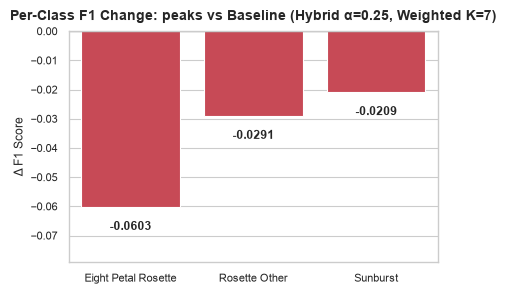

Experiment,Class,Δ Precision,Δ Recall,Δ F1
peaks,eight_petal_rosette,-0.0425,-0.0882,-0.0603
peaks,rosette_other,-0.0686,0.0000,-0.0291
peaks,sunburst,0.0000,-0.0270,-0.0209


In [167]:
not_star_classes = ["eight_petal_rosette", "rosette_other", "sunburst"]
rows = []

for experiment, records in raw_data.items():
    for item in records:
        for cls, metrics in item["metrics"]["per_class_metrics"].items():
            rows.append({
                "experiment": experiment,
                "alpha": item["alpha"],
                "strategy": item["strategy"],
                "k": item["k"],
                "class": cls,
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "f1": metrics["f1-score"],
            })

per_class = pd.DataFrame(rows)

keys = ["alpha", "strategy", "k", "class"]
baseline_classes = per_class[per_class["experiment"] == "baseline"].drop(
    columns="experiment"
)

class_comparison = per_class[
    per_class["experiment"] != "baseline"
].merge(
    baseline_classes,
    on=keys,
    suffixes=("", "_baseline"),
    validate="many_to_one",
)

for metric in ["precision", "recall", "f1"]:
    class_comparison[f"delta_{metric}"] = (
        class_comparison[metric] - class_comparison[f"{metric}_baseline"]
    )

non_star_comparison = class_comparison[
    (class_comparison["alpha"] == 0.25)
    & (class_comparison["strategy"] == "weighted")
    & (class_comparison["k"] == 7)
    & (class_comparison["class"].isin(not_star_classes))
]

display_df = non_star_comparison[
    ["experiment", "class", "delta_precision", "delta_recall", "delta_f1"]
].copy()

display_df.columns = ["Experiment", "Class", "Δ Precision", "Δ Recall", "Δ F1"]
delta_cols = ["Δ Precision", "Δ Recall", "Δ F1"]

max_delta = display_df[delta_cols].abs().max().max() if not display_df[delta_cols].empty else 0.1

styled_non_stars = display_df.style.format(precision=4) \
    .background_gradient(subset=delta_cols, cmap='RdYlGn', vmin=-max_delta, vmax=max_delta) \
    .hide(axis="index")


# Plot data
plot_data = non_star_comparison.copy()
plot_data['class_label'] = plot_data['class'].str.replace('_', ' ').str.title()
plot_data['Improvement'] = plot_data['delta_f1'] > 0

plt.figure(figsize=(4.5, 3))
sns.set_theme(style="whitegrid")
sns.set_context("paper", font_scale=0.9)

ax = sns.barplot(
    data=plot_data,
    x='class_label',
    y='delta_f1',
    hue='Improvement',
    palette={True: '#28a745', False: '#dc3545'},
    legend=False
)

plt.axhline(0, color='black', linewidth=0.8)

for p in ax.patches:
    val = p.get_height()
    ax.annotate(
        f"{val:+.4f}",
        (p.get_x() + p.get_width() / 2.0, val),
        ha='center',
        va='bottom' if val >= 0 else 'top',
        xytext=(0, 2 if val >= 0 else -10),
        textcoords='offset points',
        fontsize=8.5,
        fontweight='bold'
    )

plt.title(f"Per-Class F1 Change: {selected_experiment} vs Baseline (Hybrid α=0.25, Weighted K=7)",
    fontsize=10, pad=8, fontweight="bold")
plt.xlabel('', fontsize=9)
plt.ylabel('Δ F1 Score', fontsize=8.5)

plt.xticks(fontsize=8)
plt.yticks(fontsize=8)

y_min, y_max = ax.get_ylim()
ax.set_ylim(y_min * 1.25 if y_min < 0 else y_min, y_max * 1.25 if y_max > 0 else y_max)

plt.tight_layout()
plt.show()

display(styled_non_stars)

In [168]:
def load_predictions(path):
    with path.open(encoding="utf-8") as f:
        return pd.DataFrame(json.load(f))

base = load_predictions(results_root / "v0.2_dev_baseline/voting_predictions.json")
experiment = load_predictions(available_paths[selected_experiment].parent / "voting_predictions.json")

print(f"Prediction comparison: baseline vs {selected_experiment}")

# Focus: Hybrid Weighted K=7
def select_config(df):
    return df[(df["alpha"] == 0.25) & (df["strategy"] == "weighted") & (df["k"] == 7)].copy()

base = select_config(base)
experiment = select_config(experiment)

keys = ["query_id", "artifact_id", "fold", "true_class"]

transitions = base.merge(experiment, on=keys, suffixes=("_baseline", f"_experiment"), validate="one_to_one")

assert len(transitions) == 237, "Check missing or duplicated queries."
assert len(base) == len(experiment) == len(transitions) == 237, ("Missing, duplicated, or mismatched queries.")

transitions["baseline_correct"] = (transitions["predicted_class_baseline"] == transitions["true_class"])
transitions["experiment_correct"] = (transitions["predicted_class_experiment"] == transitions["true_class"])
transitions["transition"] = transitions.apply(
    lambda r:
        "rescued" if not r.baseline_correct and r.experiment_correct
        else "regressed" if r.baseline_correct and not r.experiment_correct
        else "both_correct" if r.baseline_correct and r.experiment_correct
        else "both_wrong",
    axis=1,
)

Prediction comparison: baseline vs peaks


In [169]:
display(Markdown("### Overall Prediction Transition Counts"))
display(transitions["transition"].value_counts())

### Overall Prediction Transition Counts

transition
both_correct    140
both_wrong       82
rescued           8
regressed         7
Name: count, dtype: int64

In [170]:
display(Markdown("### Prediction Transitions by True Motif Class"))
summary = pd.crosstab(transitions["true_class"], transitions["transition"])
display(summary)

### Prediction Transitions by True Motif Class

transition,both_correct,both_wrong,regressed,rescued
true_class,,,,
eight_petal_rosette,23,8,3,0
eight_pointed_star,41,8,0,3
five_pointed_star,20,19,1,2
rosette_other,16,15,0,0
six_pointed_star,20,20,0,1
sunburst,20,12,3,2


In [171]:
changed = transitions[ transitions["predicted_class_baseline"] != transitions["predicted_class_experiment"]]

display(changed[["query_id", "true_class", "predicted_class_baseline", "predicted_class_experiment", "transition"]])
print(f"Changed predictions on crop level: {len(changed)} / {len(transitions)}")

,query_id,true_class,predicted_class_baseline,predicted_class_experiment,transition
5,eight_petal_rosette\4636_primary_occ_01.jpg,eight_petal_rosette,eight_petal_rosette,rosette_other,regressed
8,eight_pointed_star\156380_primary_occ_01.jpg,eight_pointed_star,eight_petal_rosette,eight_pointed_star,rescued
9,eight_pointed_star\156380_primary_occ_02.jpg,eight_pointed_star,six_pointed_star,eight_pointed_star,rescued
26,five_pointed_star\europeana_916110_smm_vm_obje...,five_pointed_star,eight_pointed_star,five_pointed_star,rescued
46,sunburst\52487_primary_occ_01.jpg,sunburst,negative_control,eight_petal_rosette,both_wrong
69,five_pointed_star\33779_primary_occ_01.jpg,five_pointed_star,five_pointed_star,six_pointed_star,regressed
96,sunburst\446122_primary_occ_01.jpg,sunburst,rosette_other,eight_petal_rosette,both_wrong
105,eight_petal_rosette\251816_primary_occ_03.jpg,eight_petal_rosette,eight_petal_rosette,rosette_other,regressed
118,five_pointed_star\557847_primary_occ_03.jpg,five_pointed_star,six_pointed_star,five_pointed_star,rescued
134,six_pointed_star\767_primary_occ_01.jpg,six_pointed_star,eight_pointed_star,five_pointed_star,both_wrong


Changed predictions on crop level: 20 / 237


In [172]:
artifact_summary = (transitions.groupby(["artifact_id", "true_class"]).agg(n_crops=("query_id", "size"),
        rescued=("transition", lambda x: (x == "rescued").sum()),
        regressed=("transition", lambda x: (x == "regressed").sum())).reset_index())

artifact_summary["net_change"] = (artifact_summary["rescued"] - artifact_summary["regressed"])

display(artifact_summary[(artifact_summary["rescued"] > 0) | (artifact_summary["regressed"] > 0)])
affected = artifact_summary.query("rescued > 0 or regressed > 0")

print(
    f"Changed predictions: "
    f"{changed['artifact_id'].nunique()} unique artifacts / "
    f"{len(changed)} changed crops / "
    f"{len(transitions)} total crops"
)

print(
    f"Accuracy changes: "
    f"{len(affected)} unique artifact-class groups / "
    f"{affected['rescued'].sum()} rescued crops / "
    f"{affected['regressed'].sum()} regressed crops"
)

,artifact_id,true_class,n_crops,rescued,regressed,net_change
3,13876,eight_petal_rosette,2,0,1,-1
7,156380,eight_pointed_star,2,2,0,2
9,188074,sunburst,1,0,1,-1
16,222169,eight_pointed_star,1,1,0,1
18,24007,sunburst,1,0,1,-1
34,251816,eight_petal_rosette,1,0,1,-1
94,33779,five_pointed_star,2,0,1,-1
97,443098,sunburst,2,1,1,0
118,454361,six_pointed_star,1,1,0,1
124,4636,eight_petal_rosette,1,0,1,-1


Changed predictions: 18 unique artifacts / 20 changed crops / 237 total crops
Accuracy changes: 13 unique artifact-class groups / 8 rescued crops / 7 regressed crops
